<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js14/TG14_1_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **JS14 - Convolutional Neural Network**
---
---
**Praktikum 1**

## Langkah 1 - Install & import library

In [1]:
!pip install -q kagglehub

In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)
pd.set_option("display.max_columns", 50)

## Langkah 2 - Load dataset dari Kaggle
File CSV dicari otomatis di folder hasil unduhan.

In [3]:
dataset_dir = Path(kagglehub.dataset_download("abiyyurasyiq/jakarta-house-price-dataset"))
csv_files = sorted(dataset_dir.rglob("*.csv"))
print("File CSV:", [f.name for f in csv_files])

df = pd.read_csv(csv_files[0])
print("Bentuk data:", df.shape)
df.head()

100%|██████████| 122k/122k [00:00<00:00, 48.2MB/s]

Extracting files...
File CSV: ['jakarta_house.csv']
Bentuk data: (10000, 9)


,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


## Langkah 3 - Eksplorasi data

In [4]:
df.info()
print("\nBaris duplikat:", df.duplicated().sum())
mv = df.isna().sum()
print("\nMissing value (hanya yang > 0):")
print(mv[mv > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  object 
 3   city           10000 non-null  object 
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), object(2)
memory usage: 703.3+ KB

Baris duplikat: 0

Missing value (hanya yang > 0):
land_area        3
building_area    5
dtype: int64


### Tentukan kolom harga
Dicari otomatis dari nama kolom yang mengandung `price`/`harga`. Jika salah, isi `TARGET` manual.

In [5]:
TARGET = None   # contoh manual: TARGET = "price_in_rp"

if TARGET is None:
    cands = [c for c in df.columns if re.search(r"price|harga", c, re.I)]
    print("Kandidat:", cands)
    TARGET = cands[0]
print("Kolom harga dipakai:", TARGET)

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df[TARGET].describe()

Kandidat: ['price']
Kolom harga dipakai: price


,price
count,1.000000e+04
mean,1.004029e+10
std,2.004519e+10
min,1.850000e+06
25%,2.500000e+09
50%,4.500000e+09
75%,9.800000e+09
max,9.000000e+11


## Langkah 4 - Pembersihan data & pembentukan label

In [6]:
data = df.drop_duplicates().copy()
data = data[data[TARGET].notna() & (data[TARGET] > 0)]

# Buang outlier ekstrem harga (di luar persentil 1-99)
lo, hi = data[TARGET].quantile([0.01, 0.99])
data = data[(data[TARGET] >= lo) & (data[TARGET] <= hi)].reset_index(drop=True)
print("Jumlah data bersih:", len(data))

# Pisahkan training dan testing SEBELUM membuat label, agar median hanya dari data training
train_df, test_df = train_test_split(data, test_size=0.2, random_state=42)

median_price = train_df[TARGET].median()
print(f"Median harga (batas murah/mahal): Rp {median_price:,.0f}")

y_train = (train_df[TARGET] > median_price).astype(int).values
y_test = (test_df[TARGET] > median_price).astype(int).values

class_names = ["murah", "mahal"]
print("Distribusi train:", dict(zip(class_names, np.bincount(y_train))))
print("Distribusi test :", dict(zip(class_names, np.bincount(y_test))))

Jumlah data bersih: 9805
Median harga (batas murah/mahal): Rp 4,500,000,000
Distribusi train: {'murah': np.int64(4022), 'mahal': np.int64(3822)}
Distribusi test : {'murah': np.int64(999), 'mahal': np.int64(962)}


## Langkah 5 - Pra-pengolahan fitur
- Kolom **harga dibuang dari fitur** (agar tidak terjadi kebocoran label).
- Kolom ID, kolom yang >50% kosong, dan kolom teks berkategori sangat banyak (judul, alamat) dibuang.
- Kolom kategorikal sisanya di-*one-hot encoding*.
- Nilai kosong diisi median training, lalu fitur distandarisasi (`StandardScaler`, di-`fit` hanya pada training).

In [7]:
MAX_CAT = 40

X_train_raw = train_df.drop(columns=[TARGET])
X_test_raw = test_df.drop(columns=[TARGET])

drop_cols = []
for c in X_train_raw.columns:
    col = X_train_raw[c]
    if re.search(r"(^|_)id$", c, re.I) or col.isna().mean() > 0.5:
        drop_cols.append(c)
    elif not pd.api.types.is_numeric_dtype(col) and col.nunique() > MAX_CAT:
        drop_cols.append(c)
    elif pd.api.types.is_numeric_dtype(col) and col.nunique() <= 1:
        drop_cols.append(c)
print("Kolom dibuang:", drop_cols)

X_train_raw = X_train_raw.drop(columns=drop_cols)
X_test_raw = X_test_raw.drop(columns=drop_cols)

cat_cols = [c for c in X_train_raw.columns if not pd.api.types.is_numeric_dtype(X_train_raw[c])]
print("Kolom kategorikal:", cat_cols)

# One-hot: kolom test disamakan dengan kolom training
X_train = pd.get_dummies(X_train_raw, columns=cat_cols, dtype=float)
X_test = pd.get_dummies(X_test_raw, columns=cat_cols, dtype=float).reindex(columns=X_train.columns, fill_value=0.0)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Bentuk input Conv1D: (sampel, jumlah_fitur, 1)
X_train_c = X_train_s[..., np.newaxis]
X_test_c = X_test_s[..., np.newaxis]
print("Bentuk X_train:", X_train_c.shape, "| X_test:", X_test_c.shape)

Kolom dibuang: ['district']
Kolom kategorikal: ['city']
Bentuk X_train: (7844, 11, 1) | X_test: (1961, 11, 1)


## Langkah 6 - Bangun model CNN (Conv1D)

In [8]:
n_features = X_train_c.shape[1]

model = models.Sequential([
    layers.Input(shape=(n_features, 1)),

    layers.Conv1D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling1D(pool_size=2),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

## Langkah 7 - Compile model

In [9]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 11, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 5, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 32)          │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 2, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,681 (45.63 KB)

 Trainable params: 11,681 (45.63 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 8 - Training
20% data training dipakai sebagai validasi, sehingga data test tetap murni untuk evaluasi akhir.

In [10]:
history = model.fit(
    X_train_c, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2,
)

Epoch 1/25
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8492 - loss: 0.3582 - val_accuracy: 0.8693 - val_loss: 0.3057
Epoch 2/25
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8856 - loss: 0.2702 - val_accuracy: 0.8770 - val_loss: 0.2784
Epoch 3/25
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8904 - loss: 0.2588 - val_accuracy: 0.8821 - val_loss: 0.2708
Epoch 4/25
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8912 - loss: 0.2528 - val_accuracy: 0.8815 - val_loss: 0.2698
Epoch 5/25
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8923 - loss: 0.2488 - val_accuracy: 0.8815 - val_loss: 0.2678
Epoch 6/25
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8935 - loss: 0.2458 - val_accuracy: 0.8840 - val_loss: 0.2650
Epoch 7/25
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8955 - loss: 0.2433 - val_accuracy: 0.8827 - val_loss: 0.2634
Epoch 8/25
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8953 - loss: 0.2411 - val_accuracy: 0.

## Langkah 9 - Evaluasi

Akurasi testing: 89.34%
              precision    recall  f1-score   support

       murah       0.88      0.92      0.90       999
       mahal       0.91      0.86      0.89       962

    accuracy                           0.89      1961
   macro avg       0.89      0.89      0.89      1961
weighted avg       0.89      0.89      0.89      1961



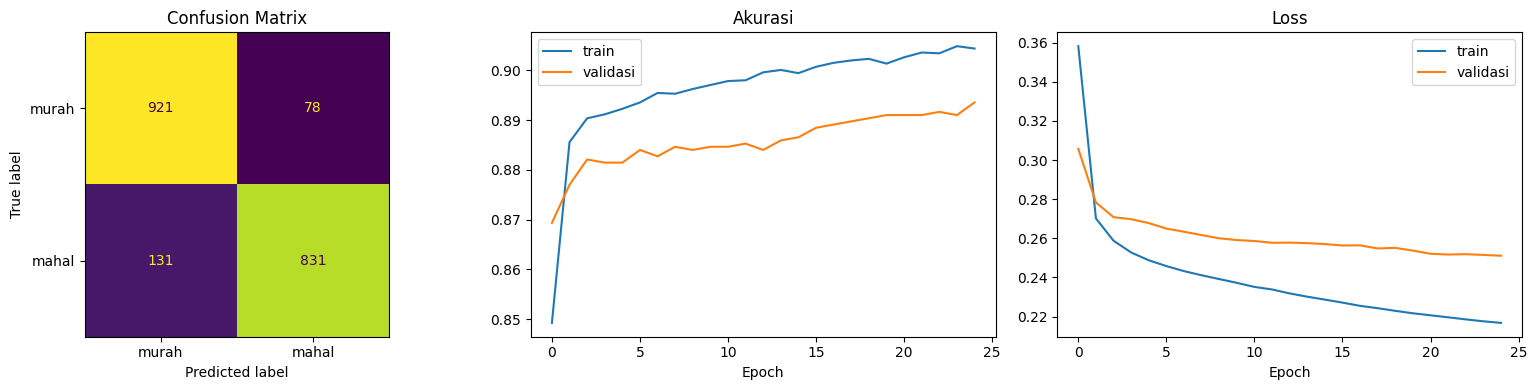

In [11]:
test_loss, test_acc = model.evaluate(X_test_c, y_test, verbose=0)
print(f"Akurasi testing: {test_acc*100:.2f}%")

y_prob = model.predict(X_test_c, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=class_names))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=class_names).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion Matrix")

ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validasi")
ax[1].set_title("Akurasi"); ax[1].set_xlabel("Epoch"); ax[1].legend()

ax[2].plot(history.history["loss"], label="train")
ax[2].plot(history.history["val_loss"], label="validasi")
ax[2].set_title("Loss"); ax[2].set_xlabel("Epoch"); ax[2].legend()
plt.tight_layout(); plt.show()

## Langkah 10 - Prediksi satu rumah (single prediction)
Mengambil satu rumah dari data test, menampilkan data aslinya, lalu memprediksi kelas harganya.

In [12]:
IDX = 0   # ubah angka ini untuk mencoba rumah lain (0 sampai jumlah data test - 1)

rumah = test_df.iloc[IDX]
fitur_tampil = [c for c in X_test_raw.columns if c in rumah.index][:10]
print("Data rumah (sebagian kolom):")
print(rumah[fitur_tampil].to_string())

prob_mahal = float(model.predict(X_test_c[IDX:IDX+1], verbose=0)[0][0])
prediksi = class_names[int(prob_mahal > 0.5)]
aktual = class_names[y_test[IDX]]

print(f"\nProbabilitas 'mahal': {prob_mahal:.4f}")
print(f"Prediksi: {prediksi} | Aktual: {aktual} | Harga asli: Rp {rumah[TARGET]:,.0f}")

Data rumah (sebagian kolom):
index                     6791
city             Jakarta Timur
bed_rooms                    3
bath_rooms                   3
carport                      2
land_area                 90.0
building_area            220.0

Probabilitas 'mahal': 0.0079
Prediksi: murah | Aktual: murah | Harga asli: Rp 3,500,000,000
